## pyrefCLASS

In [1]:
import numpy as np
from matplotlib.pyplot import *
cr = rcParams['axes.prop_cycle'].by_key()['color']

In [2]:
mass = np.logspace(-29,-27,500)

In [3]:
mass_id = [0,250,300,450]

In [5]:
dir_local = '../../data_local/2025-01-09_ALP/'
ucl = {mi: np.loadtxt(dir_local+'alpha052_p0_'+str(mass[mi])+'_N10000+cl.dat',unpack=True) for mi in mass_id}
lcl = {mi: np.loadtxt(dir_local+'alpha052_p0_'+str(mass[mi])+'_N10000+cl_lensed.dat',unpack=True) for mi in mass_id}

In [6]:
for mi in mass_id:
    print(mass[mi]) 

1e-29
1.0046250617173444e-28
1.593693530381776e-28
6.362198492657495e-28


In [7]:
l = ucl[mass_id[0]][0]
L = lcl[mass_id[0]][0]
uTT = {mi: ucl[mi][1] for mi in mass_id}
uEE = {mi: ucl[mi][2] for mi in mass_id}
uEB = {mi: ucl[mi][5] for mi in mass_id}
uBB = {mi: ucl[mi][4] for mi in mass_id}
lTT = {mi: lcl[mi][1] for mi in mass_id}
lEE = {mi: lcl[mi][2] for mi in mass_id}
lEB = {mi: lcl[mi][5] for mi in mass_id}
lBB = {mi: lcl[mi][4] for mi in mass_id}

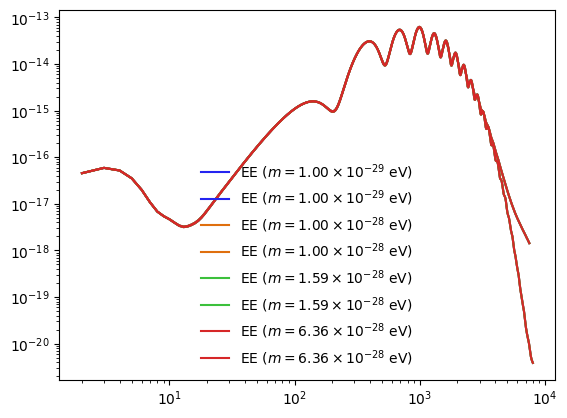

In [8]:
xscale('log')
yscale('log')
for i, mi in enumerate(mass_id):
    label = r'EE ($m='+'{:.2E}'.format(mass[mi]).replace("E", r"\times 10^{").replace("+", "")+'}$ eV)'
    plot(l,uEE[mi]*2*.3*np.pi/180.,label=label,color=cr[i])
    plot(L,lEE[mi]*2*.3*np.pi/180.,label=label,color=cr[i])
legend()

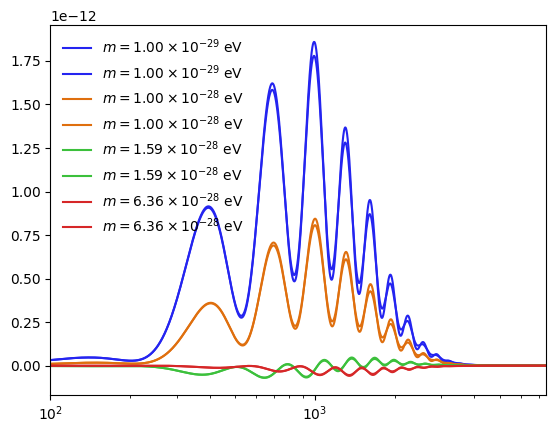

In [9]:
xscale('log')
xlim(100,7500)
for i, mi in enumerate(mass_id):
    label = r'$m='+'{:.2E}'.format(mass[mi]).replace("E", r"\times 10^{").replace("+", "")+'}$ eV'
    #plot(l,uEE[mi]*2*.3*np.pi/180.,label="",color='k')
    plot(l,uEB[mi]*30,label=label,color=cr[i])
    plot(L,lEB[mi]*30,label=label,color=cr[i])
legend()

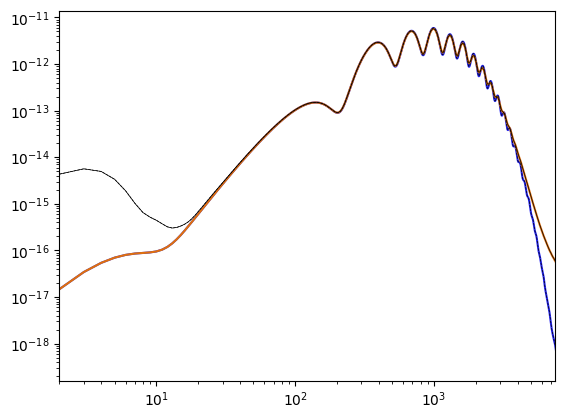

In [10]:
yscale('log')
xscale('log')
xlim(min(L),max(L))
plot(l,uEB[0]/(2*.3*np.pi/180.))
plot(L,lEB[0]/(2*.3*np.pi/180.))
plot(L,lEE[0]-lBB[0],ls='-',color='k',lw=.5)
plot(l,uEE[0],ls='--',color='k',lw=.5)

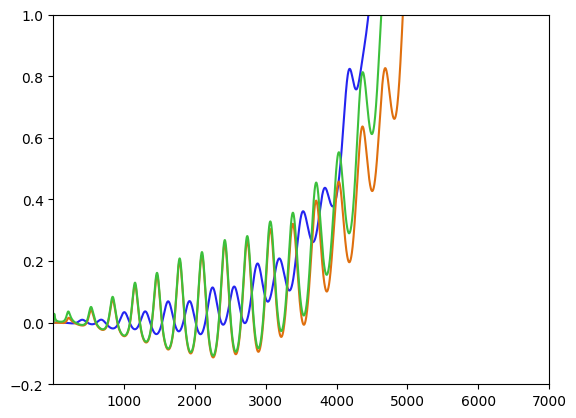

In [11]:
#yscale('log')
ylim(-0.2,1)
xlim(1,7000)
plot(L,lTT[0]/uTT[0][:7499]-1)
plot(L,lEB[0]/uEB[0][:7499]-1)
plot(L,lEE[0]/uEE[0][:7499]-1)

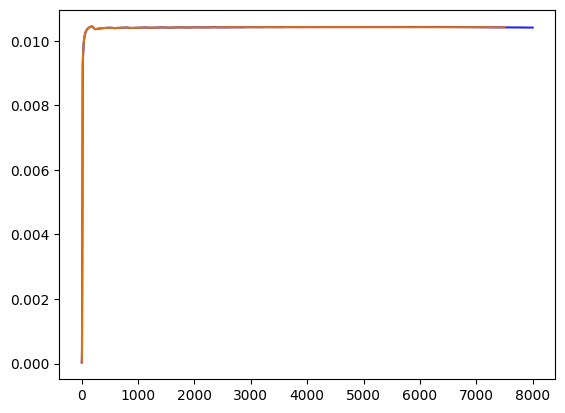

In [12]:
plot(l,uEB[0]/(uEE[0]-uBB[0]))
plot(L,lEB[0]/(lEE[0]-lBB[0]))

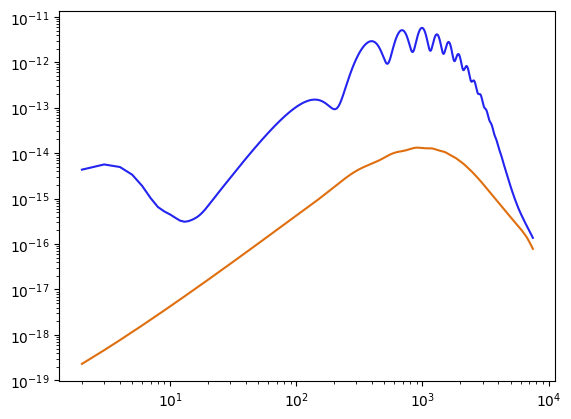

In [13]:
yscale('log')
xscale('log')
plot(L,lEE[0])
plot(L,lBB[0])

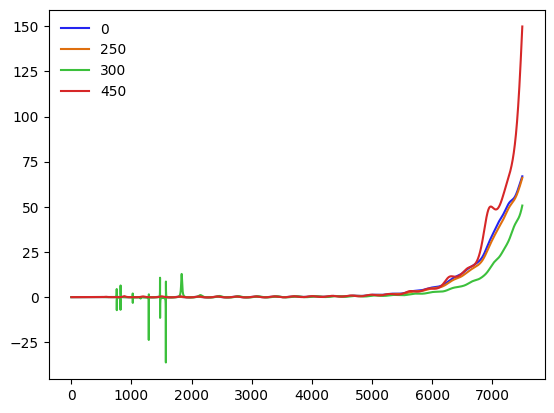

In [14]:
#xlim(2000,5000)
#ylim(-1,5)
for mi in mass_id:
    plot(L,lEB[mi]/uEB[mi][:7499]-1,label=str(mi))
legend()

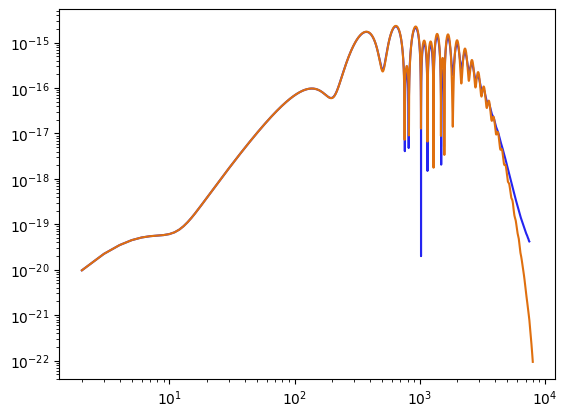

In [15]:
yscale('log')
xscale('log')
plot(L,np.abs(lEB[300]))
plot(l,np.abs(uEB[300]))